### LangGraph核心组件：流式输出
***
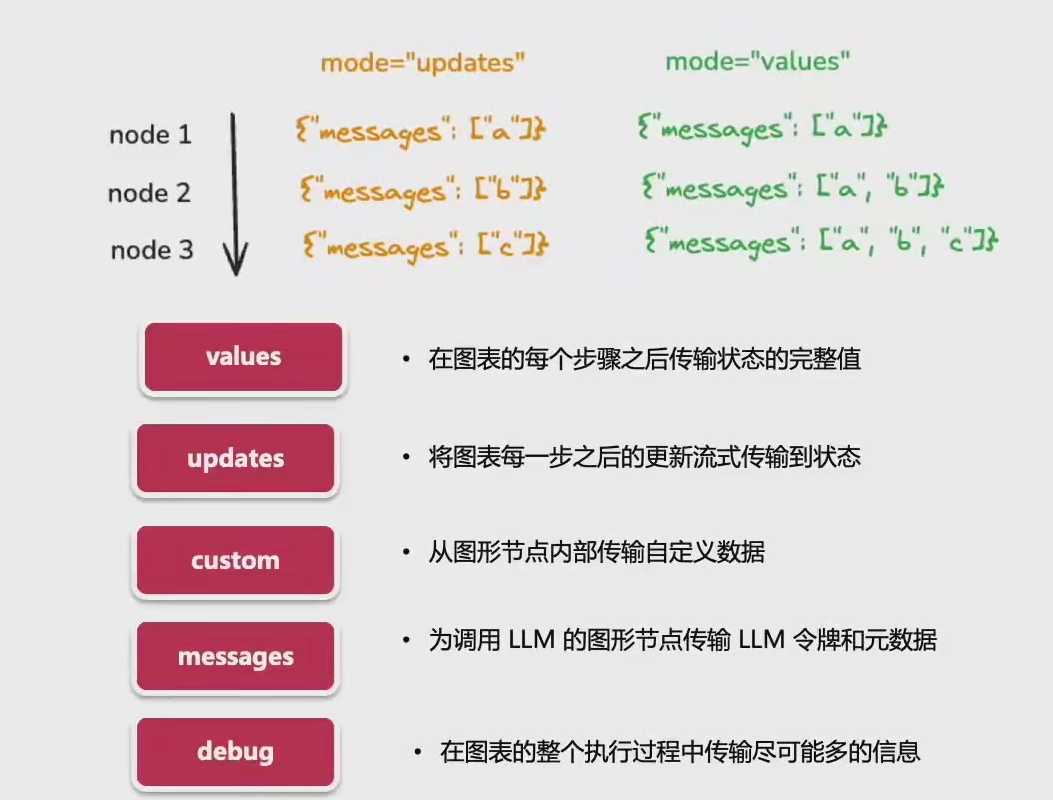

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START

class State(TypedDict):
    topic: str
    joke: str

def refine_topic(state: State):
    return {"topic": state["topic"] + "和小狗"}

def generate_joke(state: State):
    return {"joke": f"这是一个关于{state['topic']}的笑话"}

graph = (StateGraph(State) 
    .add_node(refine_topic)
    .add_node(generate_joke)
    .add_edge(START, "refine_topic")
    .add_edge("refine_topic", "generate_joke")
    .compile())

stream_mode="values"
***

In [4]:
for chunk in graph.stream(
    {"topic": "冰淇淋"},
    stream_mode="values",
):
    print(chunk)

{'topic': '冰淇淋'}
{'topic': '冰淇淋和小狗'}
{'topic': '冰淇淋和小狗', 'joke': '这是一个关于冰淇淋和小狗的笑话'}


stream_mode="updates"
***

In [5]:
for chunk in graph.stream(
    {"topic": "冰淇淋"},
    stream_mode="updates",
):
    print(chunk)

{'refine_topic': {'topic': '冰淇淋和小狗'}}
{'generate_joke': {'joke': '这是一个关于冰淇淋和小狗的笑话'}}


stream_mode="debug"
***

In [6]:
for chunk in graph.stream(
    {"topic": "冰淇淋"},
    stream_mode="debug",
):
    print(chunk)

{'step': 1, 'timestamp': '2026-10-27T09:59:55.647994+00:00', 'type': 'task', 'payload': {'id': '89efa438-fe77-103e-b33f-f32595b3f277', 'name': 'refine_topic', 'input': {'topic': '冰淇淋'}, 'triggers': ('branch:to:refine_topic',)}}
{'step': 1, 'timestamp': '2026-10-27T09:59:55.648342+00:00', 'type': 'task_result', 'payload': {'id': '89efa438-fe77-103e-b33f-f32595b3f277', 'name': 'refine_topic', 'error': None, 'result': {'topic': '冰淇淋和小狗'}, 'interrupts': []}}
{'step': 2, 'timestamp': '2026-10-27T09:59:55.648476+00:00', 'type': 'task', 'payload': {'id': '94a6d05f-db69-8ac8-cb5b-b769653cfeb1', 'name': 'generate_joke', 'input': {'topic': '冰淇淋和小狗'}, 'triggers': ('branch:to:generate_joke',)}}
{'step': 2, 'timestamp': '2026-10-27T09:59:55.648680+00:00', 'type': 'task_result', 'payload': {'id': '94a6d05f-db69-8ac8-cb5b-b769653cfeb1', 'name': 'generate_joke', 'error': None, 'result': {'joke': '这是一个关于冰淇淋和小狗的笑话'}, 'interrupts': []}}


stream_mode="messages"
***

In [7]:
from dotenv import load_dotenv
import os
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, START
from typing import TypedDict

load_dotenv()

deepseek = ChatDeepSeek(
    model = "deepseek-ai/DeepSeek-V4-Flash",
    temperature=0.7,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

class State(TypedDict):
    topic: str
    joke: str

def refine_topic(state: State):
    return {"topic": state["topic"] + "和小狗"}

def generate_joke(state: State):
    return {"joke": f"这是一个关于{state['topic']}的笑话"}

def generate_joke(state: State):
    llm_response = deepseek.invoke([
        {
            "role": "user",
            "content": f"生成一个关于 {state['topic']} 的笑话"
        }
    ])
    return {"joke": llm_response}

graph = (
    StateGraph(State)
    .add_node(refine_topic)
    .add_node(generate_joke)
    .add_edge(START, "refine_topic")
    .add_edge("refine_topic", "generate_joke")
    .compile()
)

In [8]:
for message_chunk, metadata in graph.stream(
    {"topic": "冰淇淋"},
    stream_mode="messages",
):
    if message_chunk.content:
        print(message_chunk.content, end="|", flush=True)

一只|小狗|第一次|吃|冰淇淋|，|它|兴奋|地|伸|舌头|舔|了一口|。|突然|，|它|愣住了|，|用|爪子|捂住|脑袋|。

|主人|担心|地问|：“|怎么|啦|？”

|小狗|委屈|地说|：“|汪|！|我的|脑子|突然|开始|打|喷嚏|了|！”|